# 04 · Bayesian Hyperparameter Optimisation (Optuna)

Bayesian hyperparameter optimisation (Optuna TPE sampler) for the selected model.

Objective : mean observation-level Top-1 accuracy over 3-fold GroupKFold (groups = trip) on the
            80 TRAIN trips (tuning subsample: <= 800 labelled points per trip, for compute reasons).
Pruning   : MedianPruner on the running fold mean.
Outputs   : results/optuna_trials.csv, results/optuna_best.json, results/tuned_vs_untuned.csv,
            figures/optuna_history.png
Student-test data is used ONLY after the search, to compare untuned vs tuned.

In [1]:
import sys, time, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent          # run this notebook from the notebooks/ folder
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import GroupKFold

from pathsnap import config as C
from pathsnap.models import make_model, load_split, subsample_points, X_of, MODEL_SPECS
from pathsnap.metrics import candidate_metrics, top1_predictions, top1_accuracy

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
MODEL = "XGBoost"     # model selected in notebook 03
N_TRIALS = 30

In [3]:
def space(trial):
    if MODEL == "LightGBM":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
            min_child_samples=trial.suggest_int("min_child_samples", 5, 200, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        )
    if MODEL == "XGBoost":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            max_depth=trial.suggest_int("max_depth", 3, 10),
            min_child_weight=trial.suggest_float("min_child_weight", 0.5, 20, log=True),
            subsample=trial.suggest_float("subsample", 0.5, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        )
    if MODEL == "RandomForest":
        return dict(
            n_estimators=trial.suggest_int("n_estimators", 50, 300, step=50),
            max_depth=trial.suggest_int("max_depth", 6, 30),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50, log=True),
            max_features=trial.suggest_float("max_features", 0.2, 1.0),
            max_samples=trial.suggest_float("max_samples", 0.1, 0.6),
        )
    raise KeyError(MODEL)

In [4]:
tr_c, tr_p = load_split("train")
tu_c, tu_p = subsample_points(tr_c, tr_p, max_per_trip=800)
X, y, g = X_of(tu_c), tu_c.label.to_numpy(), tu_c.trip.to_numpy()
folds = list(GroupKFold(n_splits=3).split(X, y, g))
print(f"{MODEL}: tuning rows={len(X):,}", flush=True)

def objective(trial):
    params = space(trial)
    accs, f1s = [], []
    for k, (a, b) in enumerate(folds):
        m = make_model(MODEL, params); m.fit(X[a], y[a])
        pb = m.predict_proba(X[b])[:, 1]
        vc = tu_c.iloc[b].assign(p=pb)
        accs.append(top1_accuracy(tu_p[tu_p.trip.isin(set(vc.trip))], top1_predictions(vc)))
        f1s.append(candidate_metrics(y[b], pb)["f1_macro"])
        trial.report(float(np.mean(accs)), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("cv_f1_macro", float(np.mean(f1s)))
    return float(np.mean(accs))

study = optuna.create_study(direction="maximize", study_name=f"pathsnap_{MODEL}",
                            sampler=optuna.samplers.TPESampler(seed=C.SEED, n_startup_trials=8),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0))

XGBoost: tuning rows=480,596


[I 2026-11-18 05:55:50,423] A new study created in memory with name: pathsnap_XGBoost


### trial 0 = the untuned default configuration, so the search starts from the baseline

In [5]:
study.enqueue_trial({k: v for k, v in MODEL_SPECS[MODEL][1].items()
                     if k in ("n_estimators", "learning_rate", "num_leaves", "min_child_samples",
                              "subsample", "colsample_bytree", "max_depth")} | {"reg_lambda": 1e-3} if MODEL != "RandomForest" else {})
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)
search_s = time.time() - t0
df = study.trials_dataframe()
df.to_csv(C.RESULTS / f"optuna_trials_{MODEL}.csv", index=False)
best = study.best_params
json.dump({"model": MODEL, "best_params": best, "best_cv_top1": study.best_value,
           "n_trials": len(study.trials), "n_pruned": int((df.state == "PRUNED").sum()),
           "search_seconds": search_s, "objective": "mean 3-fold GroupKFold Top-1 accuracy (train)"},
          open(C.RESULTS / f"optuna_best_{MODEL}.json", "w"), indent=2)
print("best", best, study.best_value, f"{search_s:.0f}s", flush=True)

[I 2026-11-18 05:56:06,170] Trial 0 finished with value: 0.900120224949716 and parameters: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 1.990699667393337, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_lambda': 0.001}. Best is trial 0 with value: 0.900120224949716.


[I 2026-11-18 05:57:00,377] Trial 1 finished with value: 0.9016242923248021 and parameters: {'n_estimators': 800, 'learning_rate': 0.1205712628744377, 'max_depth': 7, 'min_child_weight': 0.8890398459575589, 'subsample': 0.5779972601681014, 'colsample_bytree': 0.4348501673009197, 'reg_lambda': 2.9154431891537547}. Best is trial 1 with value: 0.9016242923248021.


[I 2026-11-18 05:57:16,984] Trial 2 finished with value: 0.8999188324222964 and parameters: {'n_estimators': 550, 'learning_rate': 0.11114989443094977, 'max_depth': 3, 'min_child_weight': 17.898794163735268, 'subsample': 0.9162213204002109, 'colsample_bytree': 0.5274034664069657, 'reg_lambda': 0.005337032762603957}. Best is trial 1 with value: 0.9016242923248021.


[I 2026-11-18 05:57:30,579] Trial 3 finished with value: 0.8978493476535165 and parameters: {'n_estimators': 200, 'learning_rate': 0.028145092716060652, 'max_depth': 7, 'min_child_weight': 2.460208061014161, 'subsample': 0.645614570099021, 'colsample_bytree': 0.7671117368334277, 'reg_lambda': 0.003613894271216527}. Best is trial 1 with value: 0.9016242923248021.


[I 2026-11-18 05:57:47,366] Trial 4 finished with value: 0.8990649866360497 and parameters: {'n_estimators': 300, 'learning_rate': 0.03476649150592621, 'max_depth': 6, 'min_child_weight': 9.054594344647798, 'subsample': 0.5998368910791798, 'colsample_bytree': 0.708540663048167, 'reg_lambda': 0.23423849847112907}. Best is trial 1 with value: 0.9016242923248021.


[I 2026-11-18 05:57:49,036] Trial 5 pruned. 


... (21 outputs left out)

[I 2026-11-18 06:07:37,418] Trial 27 pruned. 


[I 2026-11-18 06:07:48,454] Trial 28 pruned. 


[I 2026-11-18 06:08:22,803] Trial 29 finished with value: 0.9031200578341778 and parameters: {'n_estimators': 700, 'learning_rate': 0.05760345546210345, 'max_depth': 6, 'min_child_weight': 0.514935123851333, 'subsample': 0.8075229530089713, 'colsample_bytree': 0.7109394684006103, 'reg_lambda': 0.0033532576310608196}. Best is trial 29 with value: 0.9031200578341778.


best {'n_estimators': 700, 'learning_rate': 0.05760345546210345, 'max_depth': 6, 'min_child_weight': 0.514935123851333, 'subsample': 0.8075229530089713, 'colsample_bytree': 0.7109394684006103, 'reg_lambda': 0.0033532576310608196} 0.9031200578341778 752s


### untuned vs tuned: identical protocol (5-fold GroupKFold CV on train subsample, then student test)

{'model': 'XGBoost', 'version': 'untuned', 'params': '{}', 'cv_f1_macro': np.float64(0.9395036481275889), 'cv_f1_macro_std': np.float64(0.0077308265055441375), 'cv_top1': np.float64(0.8972219149825756), 'test_top1': 0.9072283489259395, 'test_f1_macro': 0.940280334187112, 'test_log_loss': 0.0678318664431572, 'fit_s': 10.296309232711792, 'inference_ms_per_1k_rows': 1.8566732100017334}


{'model': 'XGBoost', 'version': 'tuned', 'params': '{"n_estimators": 700, "learning_rate": 0.05760345546210345, "max_depth": 6, "min_child_weight": 0.514935123851333, "subsample": 0.8075229530089713, "colsample_bytree": 0.7109394684006103, "reg_lambda": 0.0033532576310608196}', 'cv_f1_macro': np.float64(0.9405867081380483), 'cv_f1_macro_std': np.float64(0.007259688871282983), 'cv_top1': np.float64(0.899520804730232), 'test_top1': 0.909214446244708, 'test_f1_macro': 0.9419276169641355, 'test_log_loss': 0.06716993451118469, 'fit_s': 24.816282272338867, 'inference_ms_per_1k_rows': 5.413124498737953}


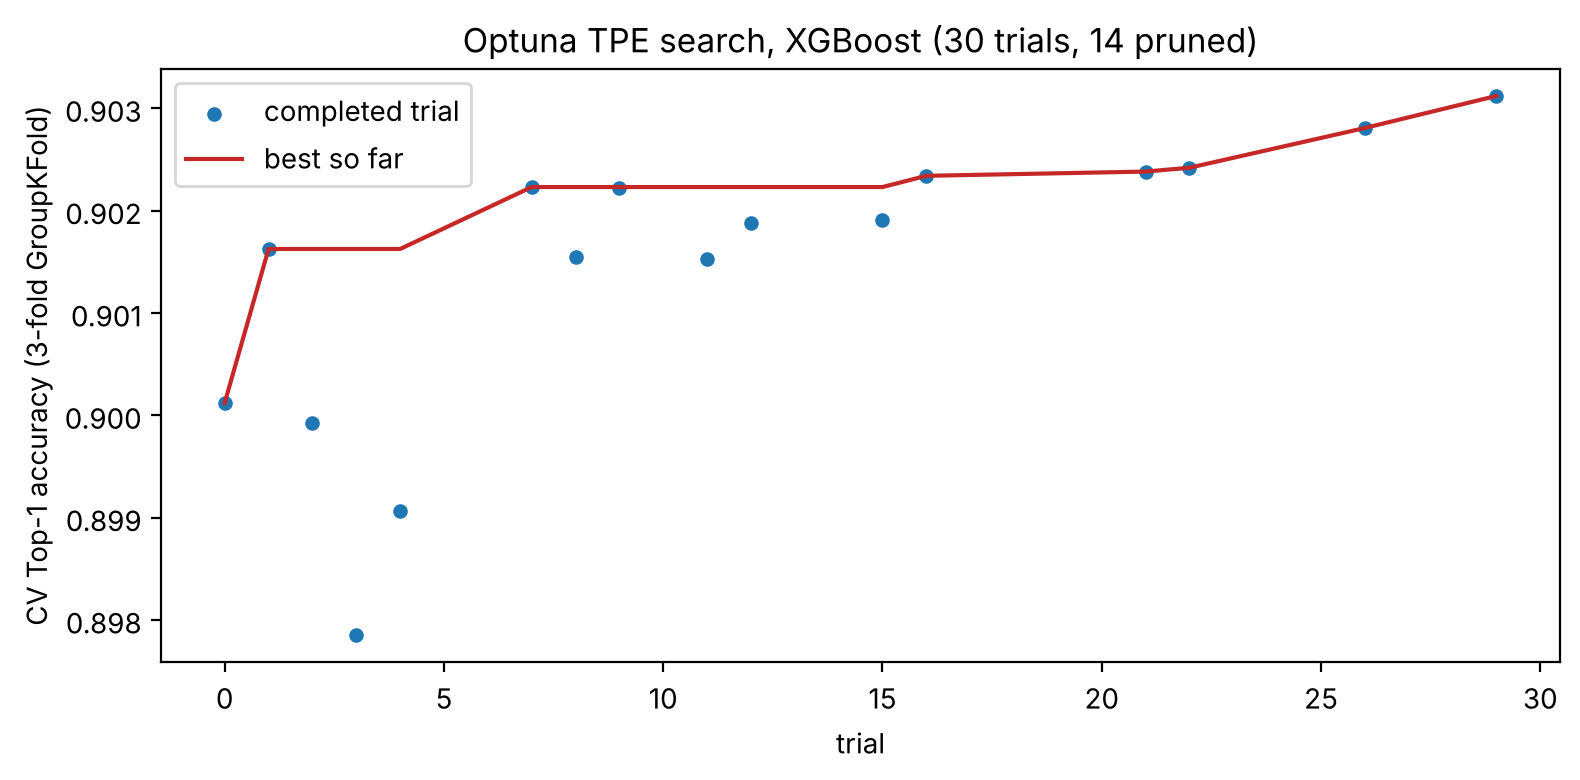

In [6]:
from importlib import import_module
full_c, full_p = subsample_points(tr_c, tr_p)
Xf, yf, gf = X_of(full_c), full_c.label.to_numpy(), full_c.trip.to_numpy()
te_c, te_p = load_split("student_test")
f5 = list(GroupKFold(n_splits=5).split(Xf, yf, gf))
rows = []
for tag, params in [("untuned", {}), ("tuned", best)]:
    cvf1, cvacc = [], []
    for a, b in f5:
        m = make_model(MODEL, params); m.fit(Xf[a], yf[a]); pb = m.predict_proba(Xf[b])[:, 1]
        cvf1.append(candidate_metrics(yf[b], pb)["f1_macro"])
        vc = full_c.iloc[b].assign(p=pb)
        cvacc.append(top1_accuracy(full_p[full_p.trip.isin(set(vc.trip))], top1_predictions(vc)))
    m = make_model(MODEL, params); t0 = time.time(); m.fit(Xf, yf); fit_s = time.time() - t0
    t0 = time.time(); pte = m.predict_proba(X_of(te_c))[:, 1]; inf_s = time.time() - t0
    cm = candidate_metrics(te_c.label.to_numpy(), pte)
    acc = top1_accuracy(te_p, top1_predictions(te_c.assign(p=pte)))
    rows.append(dict(model=MODEL, version=tag, params=json.dumps(params), cv_f1_macro=np.mean(cvf1),
                     cv_f1_macro_std=np.std(cvf1), cv_top1=np.mean(cvacc), test_top1=acc,
                     test_f1_macro=cm["f1_macro"], test_log_loss=cm["log_loss"], fit_s=fit_s,
                     inference_ms_per_1k_rows=1e6 * inf_s / len(te_c)))
    print(rows[-1], flush=True)
pd.DataFrame(rows).to_csv(C.RESULTS / "tuned_vs_untuned.csv", index=False)

import matplotlib.pyplot as plt
comp = df[df.state == "COMPLETE"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(comp.number, comp.value, s=18, label="completed trial")
ax.plot(comp.number, comp.value.cummax(), color="#c62828", label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("CV Top-1 accuracy (3-fold GroupKFold)")
ax.set_title(f"Optuna TPE search, {MODEL} ({len(df)} trials, {int((df.state=='PRUNED').sum())} pruned)")
ax.legend(); fig.tight_layout(); fig.savefig(C.FIGURES / "optuna_history.png", dpi=130)

### Saved figures

optuna_history.png


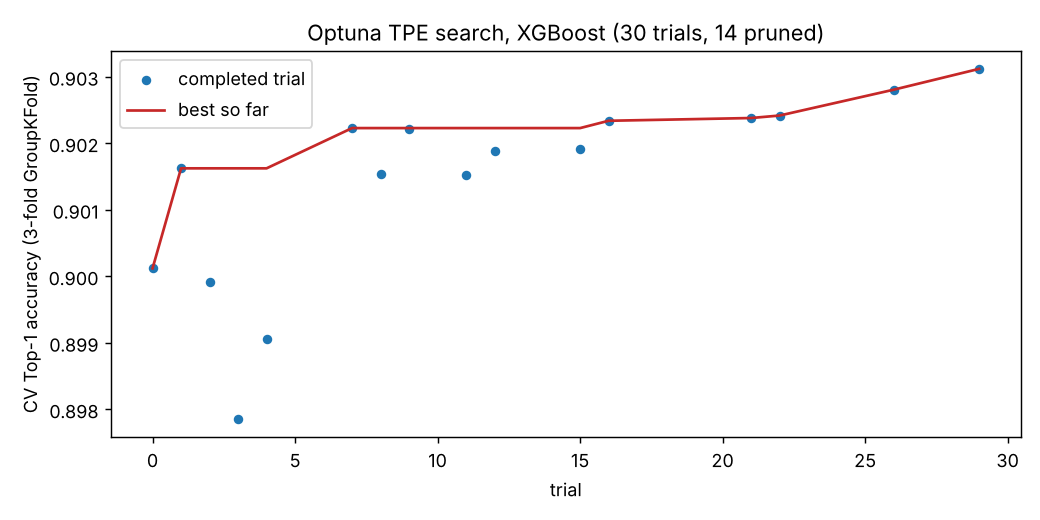

In [7]:
from IPython.display import Image, display
for f in sorted(C.FIGURES.glob("optuna_history.png")):
    print(f.name); display(Image(str(f), width=800))